# Analysis of Movies That Matter Festival
Authors: Luiza Filip, Minja Cvetkovski, Andreea Ion 

In this notebook, we will upload the csv file we created during preservation and use different libraries to generate visualizations that will allow us to make our analysis

## Importing Libraries

In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.io as pio
import re
import plotly.express as px

## Loading data
The first thing we want to do is load our csv file that we just created in *Preservation.ipynb*. We are also going to check the first 5 rows to make sure everything is in place.

In [114]:
df = pd.read_csv("df_mtmf.csv")
df.head()

,movie_url,title,description,themes,relevant_countries,mtmf_year,director,producer,years,country_of_production,duration,spoken_languages,subtitles,production_companies,world_sales
0,https://moviesthatmatter.nl/en/film/chicagogir...,#chicagoGirl – The Social Network Takes on a D...,The 19-year-old Ala’a Basatneh helps coordinat...,"['Activism and human rights defenders', 'Democ...","['Syria', 'United States']",2014,['Joe Piscatella'],"['Joe Piscatella, Mike Rinehart']",2013.0,"['United States, Syria']",74.0,"['Arabic, English']",['EN'],['Revolutio LLC.'],['Ro*co Films International']
1,https://moviesthatmatter.nl/en/film/10-conditi...,The 10 Conditions of Love,Rebiya Kadeer once embodied China’s economic s...,"['Activism and human rights defenders', 'Cultu...","['China', 'Taiwan', 'Tibet', 'Turkey']",2010,['Jeff Daniels'],['John Lewis'],2009.0,"['United States, Australia']",53.0,['English'],['EN'],['Arcimedia'],['TVF International']
2,https://moviesthatmatter.nl/en/film/107-mothers,107 Mothers,"In a Ukrainian women’s prison, inmate Lesya ha...","['Prison and detention', ""Women's rights""]",['Ukraine'],2022,['Péter Kerekes'],['Ivan Ostrochovský'],2021.0,"['Slovakia, Czech Republic, Ukraine']",93.0,"['Russian, Ukrainian']",['NL'],['Punkchart Films'],['Films Boutique']
3,https://moviesthatmatter.nl/en/film/12-years-a...,12 Years A Slave,Touching and thrilling movie based on the memo...,"['Democracy and politics', 'Racism and/or disc...",['United States'],2014,['Steve McQueen'],"['Dede Gardner, Anthony Katagas']",2013.0,"['United States, United Kingdom']",134.0,['English'],['NL'],['New Regency Pictures'],['Lionsgate']
4,https://moviesthatmatter.nl/en/film/143-sahara...,143 Sahara Street,"In her small shop, in the vast Algerian Sahara...","[""Women's rights""]",['Algeria'],2020,['Hassen Ferhani'],NaN,2019.0,"['Algeria, Qatar, France']",104.0,['Arabic'],['EN'],NaN,['Pascale Ramonda']


Now that we have loaded our dataframe, let's do the first analysis on the column Themes:

## Visualizing Themes

### Step 1: Counting the themes
ince the CSV saved the list of themes as a single string (e.g., "['War and armed conflict', 'Democracy and politics']"), we first need to convert that string back into a clean Python list so we can count each theme separately. Here, we define the function __split_themes__ to clean and return a list of all the themes.Then, we count each occurence:

In [115]:
def split_themes(x):
    if pd.isna(x):
        return []
    s = str(x).strip()

    #remove outer [ ] if present
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)

    #split on comma that separates items (handles both ', ' and ", ")
    parts = re.split(r"\s*,\s*", s)

    #remove wrapping quotes from each item
    parts = [re.sub(r"^['\"]|['\"]$", "", p.strip()) for p in parts]

    #drop empty ones
    return [p for p in parts if p]

themes_series = df["themes"].apply(split_themes).explode()
theme_counts = themes_series.value_counts()
theme_counts.head(20)

themes
War and armed conflict                      266
Democracy and politics                      218
Activism and human rights defenders         209
Family                                      207
Freedom of speech and expression            199
Youth and children's rights                 175
Migration and refugees                      172
Women's rights                              172
Justice and law                             159
Crimes against humanity and war crimes      138
Identity                                    126
Ecology and climate                         125
Racism and/or discrimination                123
Poverty                                     118
Health and well-being                       110
Political killings and/or disappearances     99
Culture and religion                         96
Freedom of press                             96
Crime                                        91
Police brutality                             88
Name: count, dtype: int64

### Step 2: Visualizing the Most Common Themes
Now that we have counted how often each theme appears, we select the __Top 15__ themes and plot them in a bar chart using Plotly (we also adjust the figure size, margins and x-axis label angle to make it more readable.

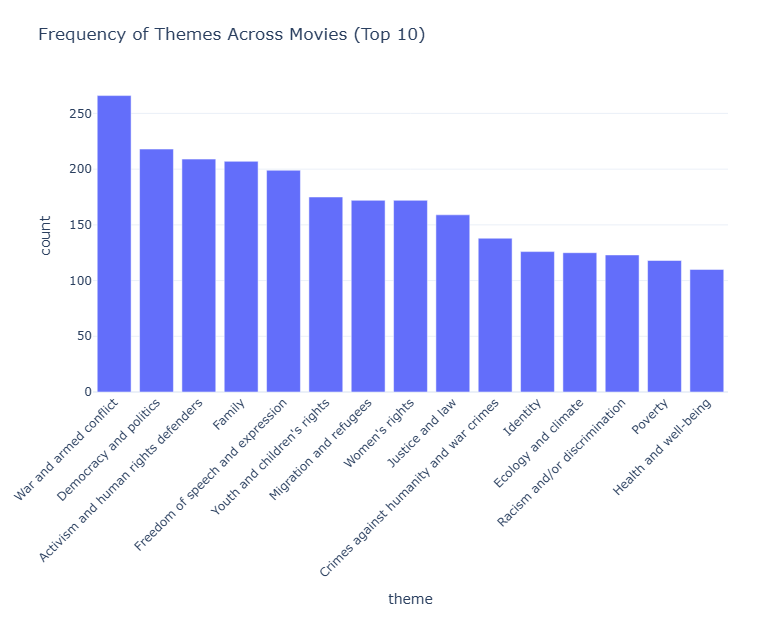

In [126]:
#stores number of the most freq themes we want to show
top_n = 15
#converting the top counts into a dataframe
top_df = theme_counts.head(top_n).reset_index()
top_df.columns = ["theme", "count"]

#creating a barchart 
fig = px.bar(
    top_df, x="theme", y="count",
    title="Frequency of Themes Across Movies (Top 10)",
    template="plotly_white"
)

#adjusting the figure size and spacing
fig.update_layout(
    width=1400,     
    height=600,     
    margin=dict(l=60, r=30, t=80, b=180)  
)
fig.update_layout(xaxis_tickangle=-45)

### Analysis
__RQ: What are the most frequent themes in our dataset?__

These themes reflect the festival’s focus on socially and politically relevant issues. The popularity of “War and armed conflict” suggests a strong emphasis on movies that deal with international wars, their effect on societies and the human experience during such crises. “Democracy and politics” and “Activism and human rights defenders” highlight the festival’s dedication to represent movies that explore civic participation, governance and the struggles of individuals and groups fighting for justice and rights. These themes were probably picked to be showcased in the festival in order to encourage reflection, conversation and understanding of significant global challenges. The fact that “Family” is a top theme can imply the exploration of personal and emotional narratives. Themes like “Youth and children’s rights”, “Migration and refugees” and “Women’s rights” also show the festival’s focus on vulnerable groups and their struggles.


## Visualizing Relevant Countries
Using the same two steps as in the case of themes we will first:
1. Split by commas
2. make the visualization using Plotly

In [135]:
def split_relevant_countries(x):
    if pd.isna(x):
        return []

    s = str(x).strip()

    #remove outer [ ] if present
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)

    #split on commas (handles both ',' and ', ')
    parts = re.split(r"\s*,\s*", s)

    #remove wrapping quotes from each item
    parts = [re.sub(r"^['\"]|['\"]$", "", p.strip()) for p in parts]

    #drop empty ones
    return [p for p in parts if p]
    
countries_series = df["relevant_countries"].apply(split_relevant_countries).explode()
#roving the accidental "The"
countries_series = countries_series[countries_series != "The"]
country_counts = countries_series.value_counts()
country_counts.head(20)

relevant_countries
United States             120
Netherlands                91
Universal                  83
France                     54
Israel                     53
Iran                       52
Russia                     48
Palestine                  44
Germany                    42
Syria                      41
China                      40
Afghanistan                39
Africa Continent           38
United Kingdom             36
Turkey                     32
India                      32
South Africa               29
Brazil                     29
Ukraine                    26
Bosnia and Herzegovina     22
Name: count, dtype: int64

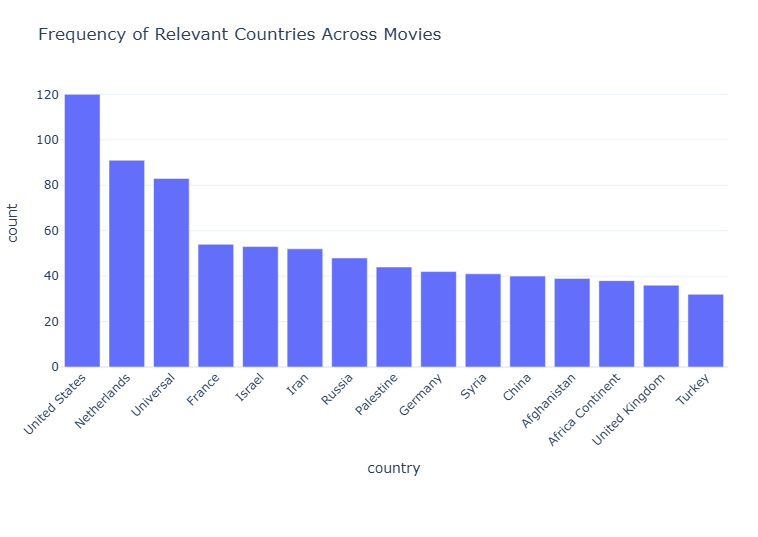

In [136]:
top_n = 15
top_c = country_counts.head(top_n).reset_index()
top_c.columns = ["country", "count"]

fig = px.bar(
    top_c,
    x="country", y="count",
    title="Frequency of Relevant Countries Across Movies",
    template="plotly_white"
)
fig.update_layout(xaxis_tickangle=-45, width=950, height=520, margin=dict(l=60, r=30, t=80, b=170))
fig.show()


### Let's interact more by visualising the globe:

C:\Users\andre\AppData\Local\Temp\ipykernel_35156\3866907448.py:17: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



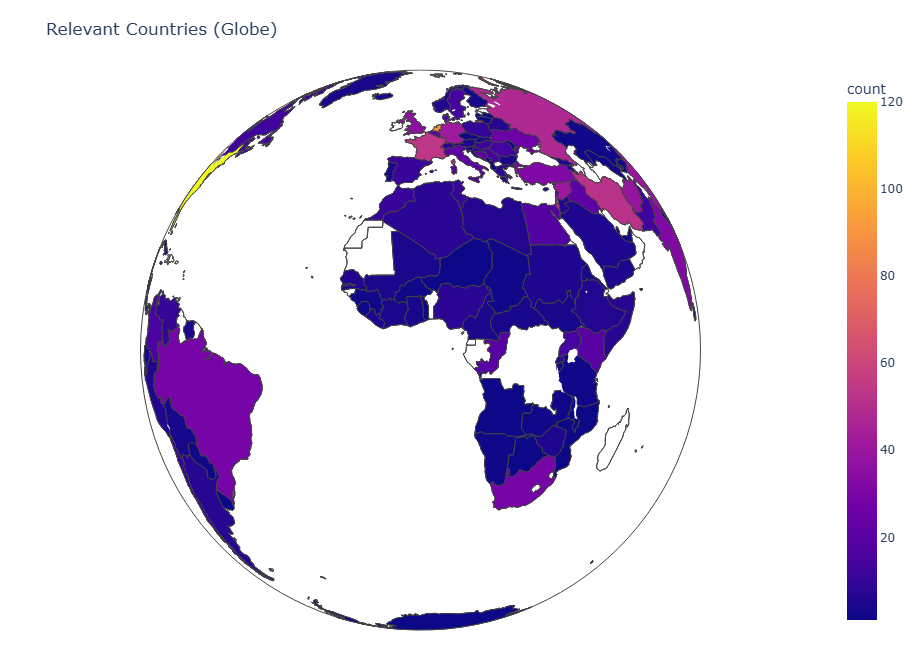

In [150]:
rel_countries = df["relevant_countries"].apply(split_relevant_countries).explode()

rel_countries = rel_countries.replace({
    "Netherlands, The": "Netherlands",
    "The Bahamas": "Bahamas"
}).dropna()

#removing blanks + the accidental "The" 
rel_countries = rel_countries[rel_countries != ""]
rel_countries = rel_countries[rel_countries != "The"]


country_counts = rel_countries.value_counts().reset_index()
country_counts.columns = ["country", "count"]

#visualizing the globe
fig = px.choropleth(
    country_counts,
    locations="country",
    locationmode="country names",
    color="count",
    projection="orthographic",
    title="Relevant Countries (Globe)",
    template="plotly_white"
)

fig.update_geos(showcoastlines=True, showcountries=True)
fig.update_layout(width=900, height=650, margin=dict(l=20, r=20, t=70, b=20))
fig.show()

### Analysis
__RQ: What are the most frequent relevant countries in our dataset?__

The United States and Netherlands dominate, likely due to their strong film industries and the festival’s location. The inclusion of countries like Israel, Iran, Palestine, Syria and Afghanistan reflects the festival’s emphasis on areas dealing with conflict, political repression or human rights issues.  The "Universal" category implies that certain movies deal with global or abstract issues that go across national boundaries.

## Visualizing Countries of Production
Similarly, we now count and visualize the frequency of the countries where the movies were produced.

In [144]:
def split_country_of_production(x):
    if pd.isna(x):
        return []
    s = str(x).strip()

    #remove outer brackets [ ... ]
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)

    #remove outer quotes '...' or "..."
    s = s.strip().strip("'").strip('"')

    #now split "United States, Syria" into ["United States", "Syria"]
    parts = [p.strip() for p in s.split(",") if p.strip()]
    return parts

countries_prod = df["country_of_production"].apply(split_country_of_production).explode()
#removing the accidental "The"
countries_prod = countries_prod[countries_prod != "The"]
country_prod_counts = countries_prod.value_counts()
country_prod_counts.head(20)

country_of_production
United States     225
France            219
Netherlands       213
Germany           142
United Kingdom    121
Belgium            77
Denmark            60
Norway             51
Canada             47
Iran               39
Sweden             39
Switzerland        32
Italy              30
Spain              29
Israel             29
Qatar              26
Poland             26
Mexico             25
Brazil             24
Palestine          24
Name: count, dtype: int64

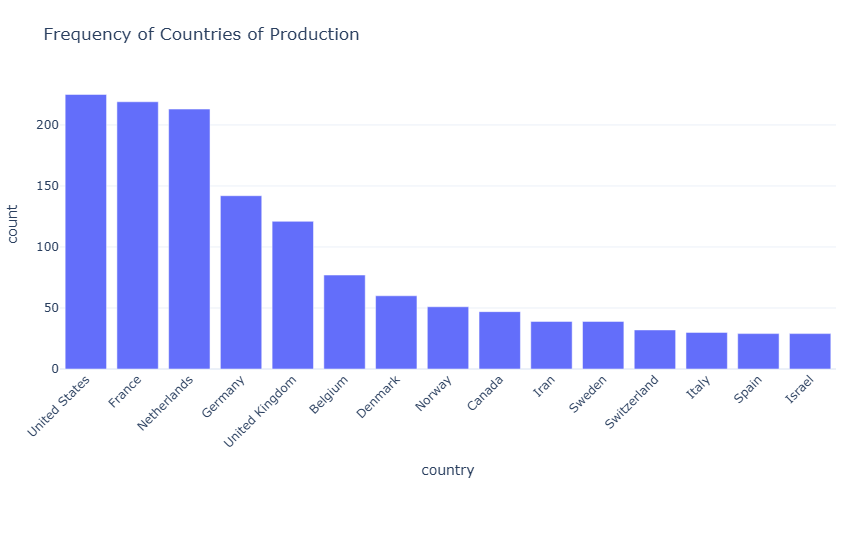

In [145]:
top_n = 15
top_cp = country_prod_counts.head(top_n).reset_index()
top_cp.columns = ["country", "count"]

fig = px.bar(
    top_cp,
    x="country", y="count",
    title="Frequency of Countries of Production",
    template="plotly_white"
)
fig.update_layout(xaxis_tickangle=-45, width=950, height=520, margin=dict(l=60, r=30, t=80, b=170))
fig.show()

### Let's interact more by visualising the globe:

C:\Users\andre\AppData\Local\Temp\ipykernel_35156\2205774480.py:9: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



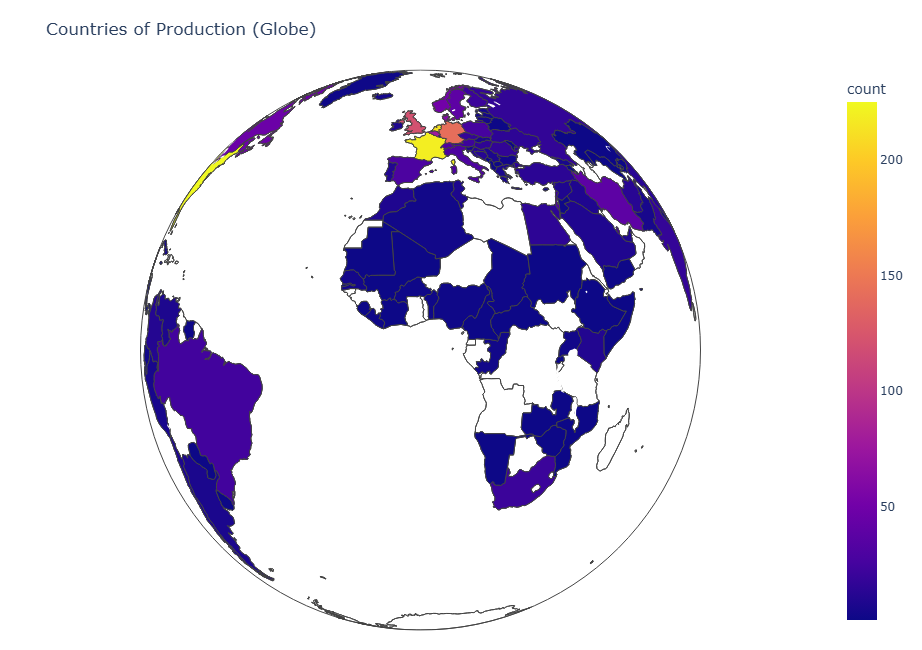

In [151]:
# quick cleanup for common sepelling differences
prod_countries = prod_countries.replace({"Netherlands, The": "Netherlands", "The Bahamas": "Bahamas"})
prod_countries = prod_countries.dropna()
prod_countries = prod_countries[prod_countries != ","]

country_counts = prod_countries.value_counts().reset_index()
country_counts.columns = ["country", "count"]

fig = px.choropleth(
    country_counts,
    locations="country",
    locationmode="country names",
    color="count",
    projection="orthographic",
    title="Countries of Production (Globe)",
    template="plotly_white",
)

fig.update_geos(showcoastlines=True, showcountries=True)
fig.update_layout(width=900, height=650, margin=dict(l=20, r=20, t=70, b=20))
fig.show()

### Analysis
__RQ: What are the most frequent countries of production in our dataset?__

As could be expected given their well-established film industries and financial systems, the United States, France, Netherlands and European nations lead in film production. The underrepresentation of developing nations may be due to differences in infrastructure, financing, and resources for making movies; this could be a topic for more study or activism.

## Visualizing the Most Spoken Languages
In order to visualize the most spoken languages, we will define a function that splits our string into a list separated by commas. This way, we can count and display the frequency using a bar plot from Plotly.

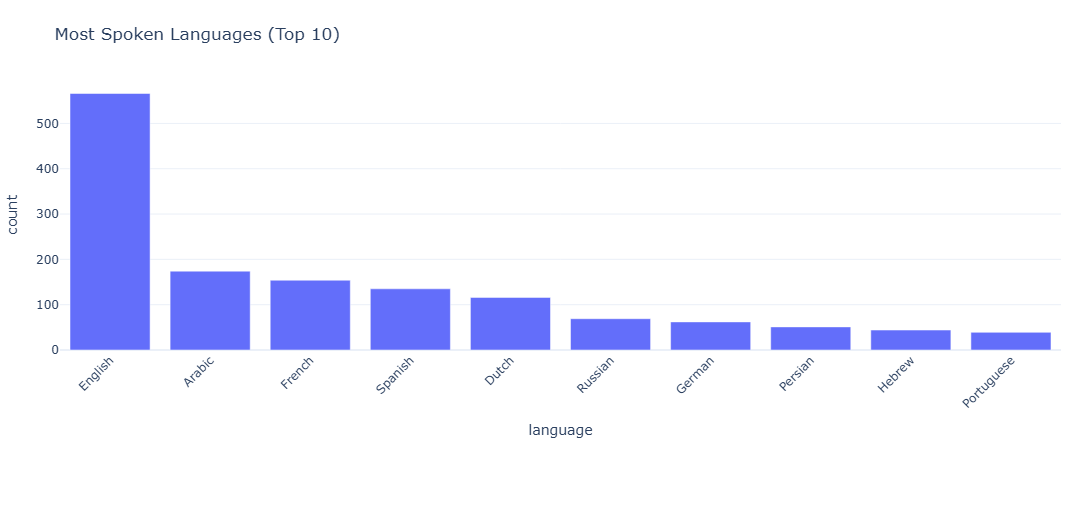

In [101]:
def split_spoken_languages(x):
    if pd.isna(x):
        return []
    s = str(x).strip()
    # remove [ ] and quotes
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)
    s = s.strip().strip("'").strip('"')
    # split "Arabic, English" -> ["Arabic","English"]
    return [p.strip() for p in s.split(",") if p.strip()]

langs = df["spoken_languages"].apply(split_spoken_languages).explode().dropna()

lang_counts = langs.value_counts()

top_n = 10
top_lang = lang_counts.head(top_n).reset_index()
top_lang.columns = ["language", "count"]

fig = px.bar(
    top_lang,
    x="language",
    y="count",
    title="Most Spoken Languages (Top 10)",
    template="plotly_white",
)
fig.update_layout(xaxis_tickangle=-45, width=950, height=520, margin=dict(l=60, r=30, t=80, b=170))
fig.show()

### Analysis:
__RQ: What are the most frequent spoken languages in our dataset?__

English’s domination aligns with its status as the universal language, which makes films accessible to a wider audience. The presence of languages like Arabic, Persian, and Hebrew may reflect the festival’s emphasis on regions experiencing conflict or political issues such as the Middle East. Given that the event takes place in the Netherlands, Dutch is also pretty represented, although not as much as we expected. The festival's international reach and its attempt to reflect voices from many cultural and geopolitical contexts are highlighted by its range of languages.

## Visualizing Language and Themes (Heatmap)

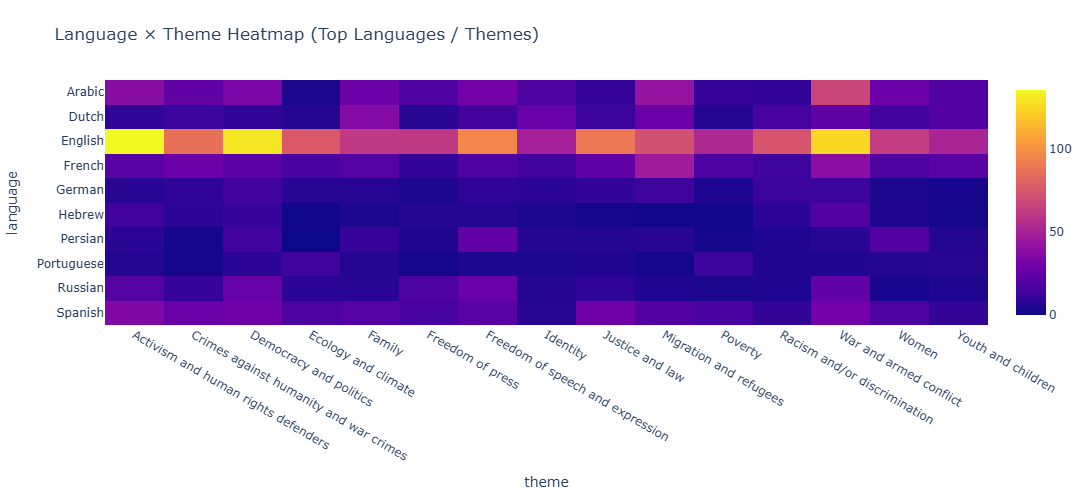

In [102]:
def parse_list_quoted(x):
    if pd.isna(x):
        return []
    return [i.strip() for i in re.findall(r"""['"]([^'"]+)['"]""", str(x)) if i.strip()]

def split_spoken_languages(x):
    if pd.isna(x):
        return []
    s = str(x).strip()
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)
    s = s.strip().strip("'").strip('"')
    return [p.strip() for p in s.split(",") if p.strip()]

#lists
df["themes_list"] = df["themes"].apply(parse_list_quoted)
df["langs_list"]  = df["spoken_languages"].apply(split_spoken_languages)

#explode both (one row per movie-language-theme)
lt = df[["themes_list","langs_list"]].explode("langs_list").explode("themes_list")
lt = lt.dropna(subset=["langs_list","themes_list"]).rename(columns={"langs_list":"language","themes_list":"theme"})

top_langs = lt["language"].value_counts().head(10).index
top_themes = lt["theme"].value_counts().head(15).index

pivot = (
    lt[lt["language"].isin(top_langs) & lt["theme"].isin(top_themes)]
    .pivot_table(index="language", columns="theme", aggfunc="size", fill_value=0)
)
#generating visualization
fig = px.imshow(
    pivot,
    title="Language × Theme Heatmap (Top Languages / Themes)",
    aspect="auto",
    template="plotly_white"
)
fig.update_layout(width=1000, height=500, margin=dict(l=80, r=30, t=80, b=80))
fig.show()

### Analysis:
__RQ: Which themes are most associated with which spoken languages in our dataset?__

*English*: High frequency across almost all themes, especially "War and armed conflict", "Democracy and politics" and "Activism and human rights defenders". This reflects the global reach and diversity of English-language films.

*Arabic*: Strong focus on "War and armed conflict", "Migration and refugees", likely reflecting the socio-political realities of the Middle East and North Africa.


## Visualizing The Most Common Themes Over Years
Here we look at how the most common themes change over time. We identify the overall **top 10** themes across the dataset and filter to only those themes. Then, we group by year and theme to count occurrences and plot a multi-line chart, where each line tracks how frequently a top theme appears in each year.


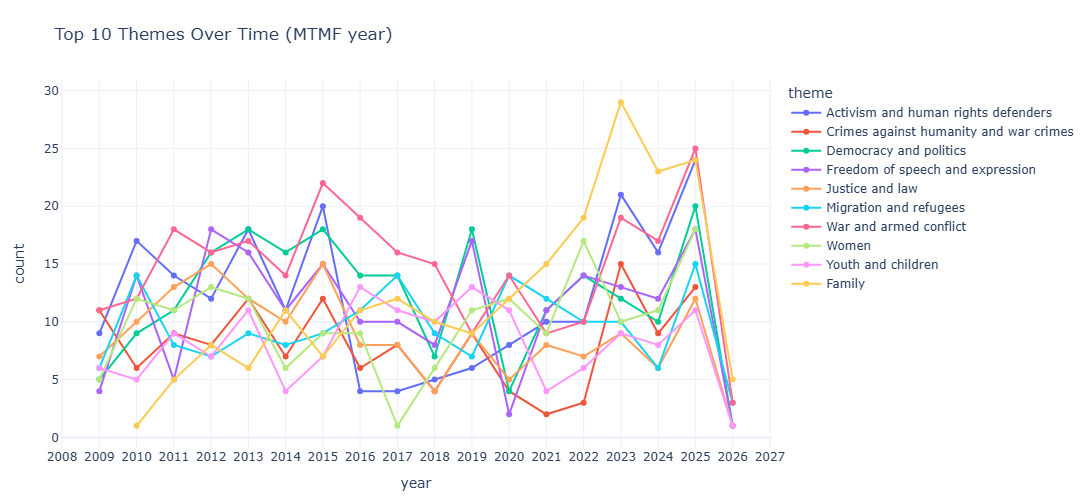

In [103]:
def parse_list_quoted(x):
    if pd.isna(x):
        return []
    return [i.strip() for i in re.findall(r"""['"]([^'"]+)['"]""", str(x)) if i.strip()]

#explode to (year, theme)
yt = (
    df[["mtmf_year", "themes"]]
    .assign(theme_list=df["themes"].apply(parse_list_quoted))
    .explode("theme_list")
    .dropna(subset=["mtmf_year", "theme_list"])
    .rename(columns={"mtmf_year": "year", "theme_list": "theme"})
)

top_n = 10
top_themes = yt["theme"].value_counts().head(top_n).index
yt = yt[yt["theme"].isin(top_themes)]

counts = yt.groupby(["year", "theme"]).size().reset_index(name="count")

fig = px.line(
    counts,
    x="year", y="count", color="theme",
    markers=True,
    title=f"Top {top_n} Themes Over Time (MTMF year)",
    template="plotly_white"
)
fig.update_layout(width=1000, height=500, margin=dict(l=60, r=30, t=80, b=50))
fig.update_xaxes(dtick=1)
fig.show()

### Analysis:
__RQ: How do themes change over time (mtmf_year) in our dataset?__

The visualization highlights how global events influence the themes explored in films. No single theme dominates every year. Most themes rise and fall, which suggests the dataset’s focus shifts over time rather than staying fixed. The peak of the "Family" theme from 2019 to 2023 suggests a growing interest in personal stories and emotional connections, possibly as a response to the bonding between close ones after the pandemic. The fluctuations in "War and armed conflict" and "Democracy and politics" align with real-world events, showing how filmmakers respond to contemporary issues. 

The sharp drop at the very end (2026+) is likely an artifact, not a real decline, often caused by incomplete data for the most recent year(s) (films from 2026 are incomplete due to the fact that the festival has not taken place yet).

## Visualizing Themes Addressed in Specific Countries
This code esentially parses and explodes the themes and relevant countries lists, cleans out the non-country labels (such as 'Universal'), then builds a country-theme frequency pivot table (top countries and themes) for a heatmap.

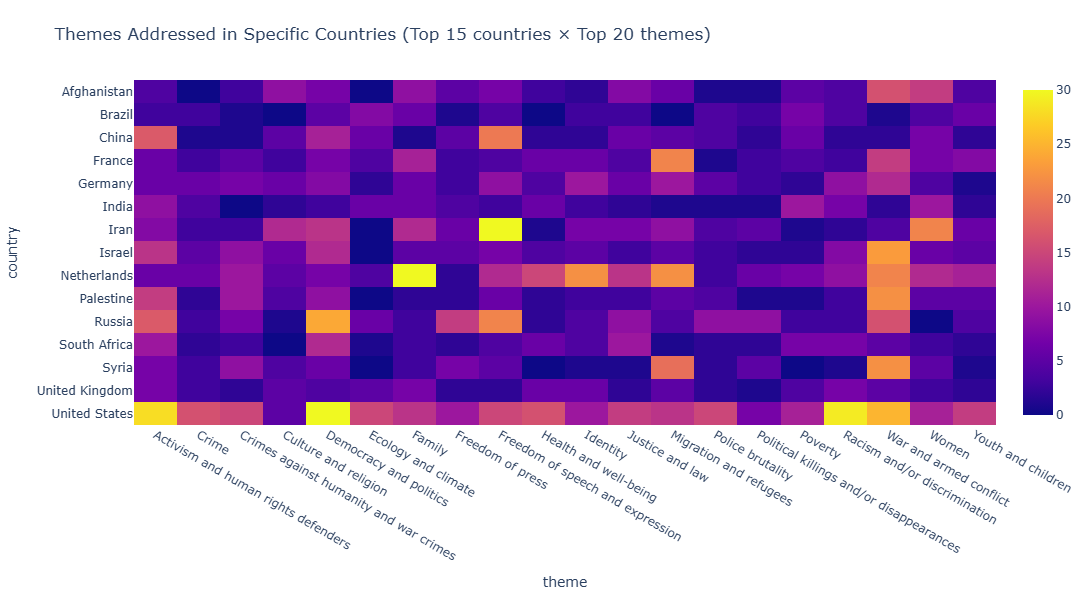

In [104]:
def parse_list_quoted(x):
    if pd.isna(x):
        return []
    return [i.strip() for i in re.findall(r"""['"]([^'"]+)['"]""", str(x)) if i.strip()]

#explode themes and relevant countries
tmp = df[["themes", "relevant_countries"]].copy()
tmp["theme"] = tmp["themes"].apply(parse_list_quoted)
tmp["country"] = tmp["relevant_countries"].apply(parse_list_quoted)

ct = (
    tmp.explode("theme")
       .explode("country")
       .dropna(subset=["theme", "country"])
)

#filter out non-country tags in relevant_countries
UNIVERSAL = {"Universal", "Worldwide", "World", "Global", "International", "Various"}
CONTINENTS = {"Africa","Asia","Europe","North America","South America","Oceania","Antarctica"}
REGIONS = {"Middle East", "North Africa"}

ct["country"] = ct["country"].replace({
    "Africa Continent": "Africa",
    "Asia Continent": "Asia",
    "Europe Continent": "Europe",
    "Continent Antarctica": "Antarctica",
    "Netherlands, The": "Netherlands",
    "The Bahamas": "Bahamas",
}).astype(str).str.strip()

ct = ct[~ct["country"].isin(UNIVERSAL | CONTINENTS | REGIONS)]
ct = ct[ct["country"] != ","]

#choose top N to keep the heatmap readable
top_countries = ct["country"].value_counts().head(15).index
top_themes = ct["theme"].value_counts().head(20).index

ct2 = ct[ct["country"].isin(top_countries) & ct["theme"].isin(top_themes)]

pivot = ct2.pivot_table(index="country", columns="theme", aggfunc="size", fill_value=0)

fig = px.imshow(
    pivot,
    aspect="auto",
    title="Themes Addressed in Specific Countries (Top 15 countries × Top 20 themes)",
    template="plotly_white"
)
fig.update_layout(width=1000, height=600, margin=dict(l=120, r=30, t=80, b=80))
fig.show()

### Analysis:
__RQ: Which top themes are most addressed in top countries?__

- *United States*: Strong focus on "Democracy and politics", "Justice and law" and "Racism and/or discrimination" reflecting its political culture and social issues.
- *Netherlands*: Also presents a wider range of topics covered in the movies although “Family” seems to be the most prominent, indicating the curatorial focus on a domestic context. 
- *Iran*: High frequency in "Freedom of speech and expression", likely due to censorship and political repression.
- *Israel and Palestine*: Dominated by "War and armed conflict", reflecting the ongoing Israeli-Palestinian conflict.
- *Syria*: Focus on "War and armed conflict" and "Migration and refugees", due to the prolonged civil war.
- *France and Germany*: Balanced representation across themes like "Democracy and politics", "Migration and refugees" and "Activism and human rights defenders", reflecting their roles in European and global human rights advocacy.


## Visualizing Theme Shares Over Time
In this chart, “share” means the proportion (percentage) of movies in a given year that include a specific theme. For each year, we take the total number of movies in the selected group, then compute:

- number of movies that include the theme
- divided by total number of movies that year

In [105]:
def parse_list_quoted(x):
    #extract items inside quotes
    if pd.isna(x):
        return []
    return [i.strip() for i in re.findall(r"""['"]([^'"]+)['"]""", str(x)) if i.strip()]

def split_spoken_languages(x):
    #for strings like ['Arabic, English'] into ['Arabic','English']
    if pd.isna(x):
        return []
    s = str(x).strip()
    s = re.sub(r"^\[\s*", "", s)
    s = re.sub(r"\s*\]$", "", s)
    s = s.strip().strip("'").strip('"')
    return [p.strip() for p in s.split(",") if p.strip()]

#building long table
tmp = df[["mtmf_year", "themes", "relevant_countries", "spoken_languages"]].copy()

tmp["theme"]    = tmp["themes"].apply(parse_list_quoted)
tmp["country"]  = tmp["relevant_countries"].apply(parse_list_quoted)
tmp["language"] = tmp["spoken_languages"].apply(split_spoken_languages)

long = (
    tmp.explode("theme")
       .explode("country")
       .explode("language")
       .dropna(subset=["mtmf_year", "theme", "country", "language"])
       .rename(columns={"mtmf_year": "year"})
)

#cleaning/filtering non-country tags in relevant_countries
UNIVERSAL  = {"Universal", "Worldwide", "World", "Global", "International", "Various"}
CONTINENTS = {"Africa","Asia","Europe","North America","South America","Oceania","Antarctica"}
REGIONS    = {"Middle East", "North Africa"}

long["country"] = long["country"].replace({
    "Africa Continent": "Africa",
    "Asia Continent": "Asia",
    "Europe Continent": "Europe",
    "Continent Antarctica": "Antarctica",
    "Netherlands, The": "Netherlands",
    "The Bahamas": "Bahamas",
}).astype(str).str.strip()

long = long[~long["country"].isin(UNIVERSAL | CONTINENTS | REGIONS)]
long = long[long["country"].ne(",")]

### Ukraine:

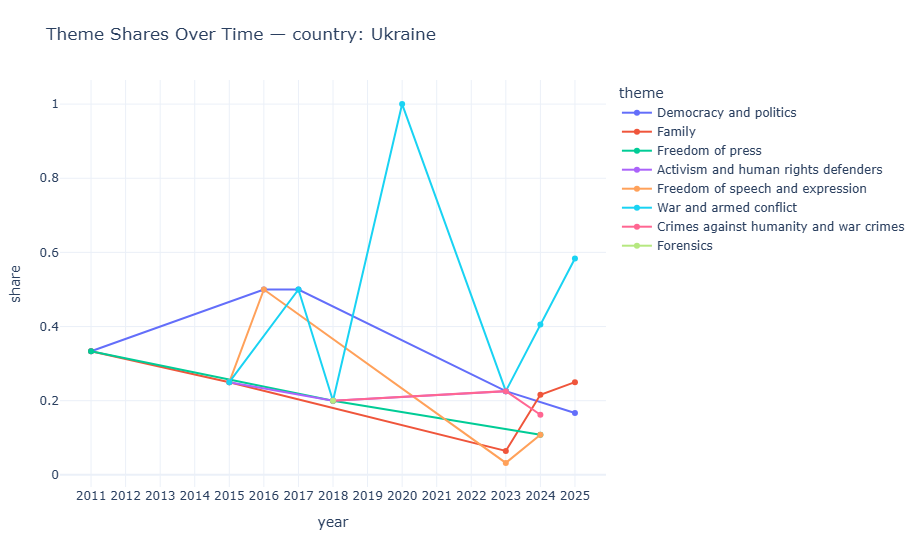

In [152]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="Ukraine", top_n=8)
fig.show()


### Analysis:
__RQ: How do the shares of the most common themes in Ukraine change over time?__

- 2011–2018: Ukraine’s theme mix is fairly spread out—several themes (like Democracy and politics, Family, and press/speech-related themes) appear at moderate shares, with no single theme dominating.

- 2020: War and armed conflict becomes overwhelmingly dominant (its share spikes to ~1.0), meaning nearly all Ukraine-tagged movies that year include that theme.

- 2023: The distribution looks more balanced again, with multiple themes sitting around similar shares (~0.2–0.25).

- 2024–2025: War and armed conflict rises again (roughly ~0.4 in 2024 and ~0.6 in 2025), while other themes remain present but smaller; Family shows a modest uptick by 2025.

Ukraine’s theme shares shift from a mixed set of themes pre-2020 to a strong conflict focus in 2020, then partial diversification, followed by conflict becoming prominent again in 2024–2025.

### United States:

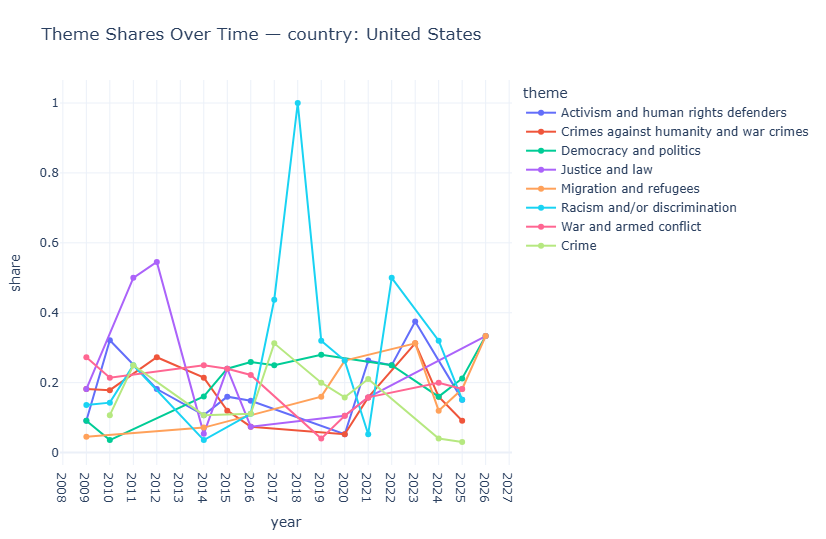

In [153]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="United States", top_n=8)
fig.show()

### Analysis:
__RQ: How do the shares of the most common themes in United States change over time?__

- 2009–2012: Justice and law is very prominent, peaking around 2011–2012 (roughly ~0.5+), while other themes (like Activism and human rights defenders and War and armed conflict) sit lower and fluctuate.

- 2013–2016: The theme mix becomes more balanced (most themes hover in the ~0.1–0.25 range with no single theme clearly dominating).

- 2017–2019: There’s a sharp, brief spike in Racism (reaching ~1.0 in 2018), meaning that year’s US-tagged movies in your data almost all included that theme; it then drops back down afterward.

- 2020–2023: Shares spread out again across multiple themes; several rise modestly around 2022–2023 (no single theme consistently above the rest for long).

- 2024–2026: The lines converge in the mid-range (~0.15–0.35), with small increases for a few themes toward 2026, suggesting a fairly mixed theme distribution in the most recent years.

The US trend is mostly diverse and mixed across years, with two standout periods: high “Justice and law” in the early 2010s and a major “Racism” spike around 2018.

### United Kingdom:

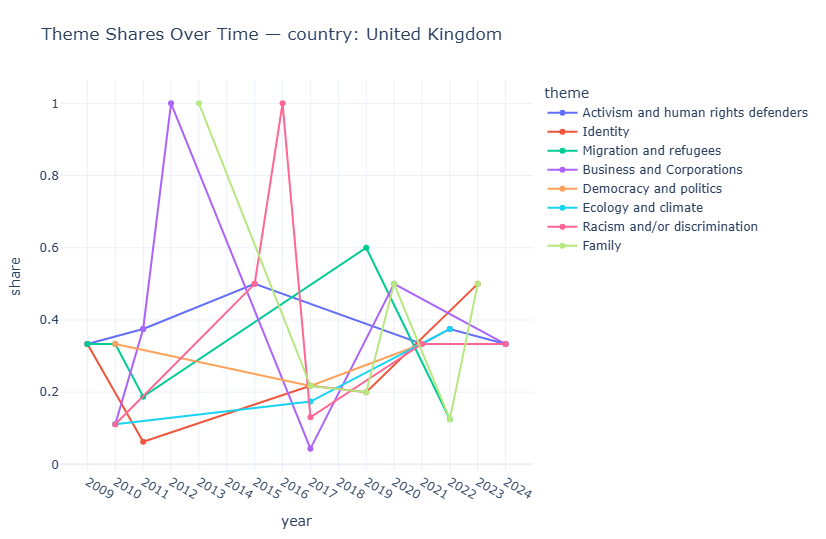

In [154]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="United Kingdom", top_n=8)
fig.show()

### Analysis:
__RQ: How do the shares of the most common themes in the United Kingdom change over time?__

- 2009–2011: Themes are fairly mixed at moderate shares (many lines around ~0.1–0.35), with no clear long-term leader yet.

- 012–2013: You see very sharp spikes where a theme hits ~1.0 (notably one in 2012 and another around 2013), meaning in those years the UK-tagged movies in your data are almost entirely associated with that single theme.

- 2015–2016: Another big concentration happens, one theme peaks at ~1.0 in 2016, while others drop, showing a temporary shift toward one dominant topic.

- 2017: Shares spread back out (most themes fall into the ~0.05–0.25 range), indicating a more diverse mix again.

- 2019–2020: One theme rises to around ~0.6 in 2019, and several themes climb together around 2020 (many near ~0.3–0.5), suggesting broader thematic coverage.

- 2021–2024: The lines converge and stabilize more, with most themes clustering around ~0.3–0.4, meaning the theme distribution becomes more balanced in recent years.

The UK pattern is more “spiky” than smoothly trending: several years show one theme dominating (shares near 1.0), but the most recent period looks more evenly distributed across themes.

### Germany

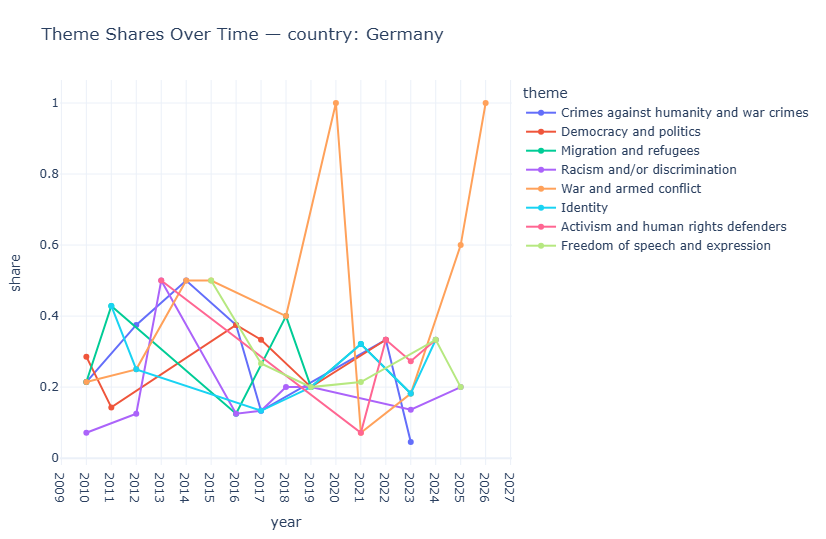

In [156]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="Germany", top_n=8)
fig.show()

### Analysis:
__RQ: How do the shares of the most common themes in Germany change over time?__

- 2010–2015: Shares are relatively balanced and mixed, with several themes (e.g., Crimes, Migration, and politics-related themes) moving between ~0.2 and ~0.5 and taking turns as the most common.

- 2016–2019: Most themes converge and stay in a narrower band (roughly ~0.15–0.4), suggesting a more even distribution with fewer extreme swings.

- 2020: War and armed conflict spikes sharply to ~1.0, meaning Germany-tagged movies in that year are almost entirely associated with that theme.

- 2021–2024: After the 2020 spike, the mix becomes diverse again: most themes sit around ~0.15–0.35, with small rises and falls rather than one dominant line.

- 025–2026: War and armed conflict rises again (about ~0.6 in 2025 and back to ~1.0 in 2026), indicating another period where conflict-focused themes dominate the Germany subset.

Germany shows a generally mixed theme profile through the 2010s, interrupted by strong conflict-dominated spikes in 2020 and again in 2025–2026.

### Mexico

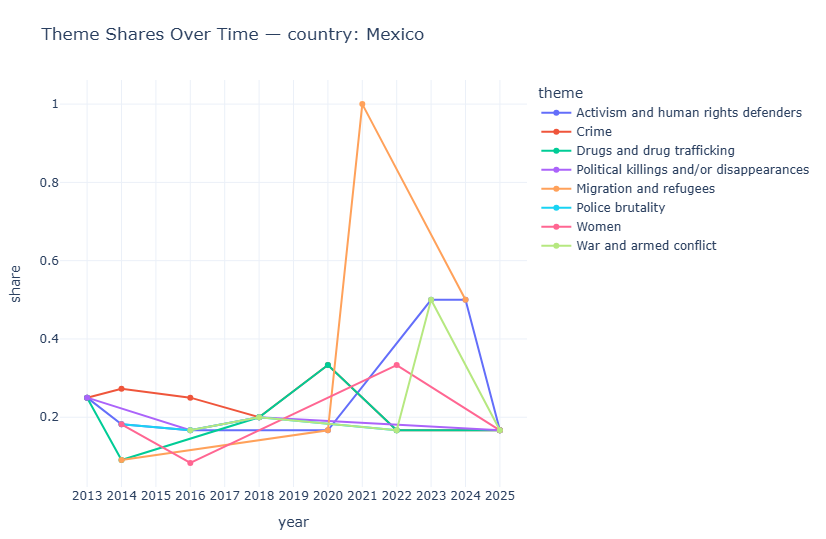

In [157]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="Mexico", top_n=8)
fig.show()

### Analysis:
__RQ:How do the shares of the most common themes in Mexico change over time?__

- 2013–2018: The distribution is fairly steady and balanced, with most themes hovering around ~0.15–0.25 and only small year-to-year shifts (no clear single dominant theme).

- 2019–2020: One theme (the green line, Drugs in your legend) rises and peaks around 2020 (~0.33), while the others stay in the same moderate range.

- 2021: There’s a major spike in the orange line (Migration and refugees), jumping to ~1.0, meaning Mexico-tagged movies in 2021 almost all include that theme.

- 2022: After the spike, the distribution becomes mixed again, with shares returning to the ~0.15–0.35 range.

- 2023–2024: Two themes become more prominent: one climbs to about ~0.5 (blue line) and another also reaches about ~0.5 (light green line), indicating a stronger concentration in those years.

- 2025: Shares drop back down and converge (most themes near ~0.17), suggesting a more even mix again (or fewer observations that year).

Mexico looks mostly stable through the mid-2010s, then shows sharp, temporary dominance by one theme in 2021, followed by another period (2023–2024) where a couple themes take a larger share before the mix evens out again.

### China

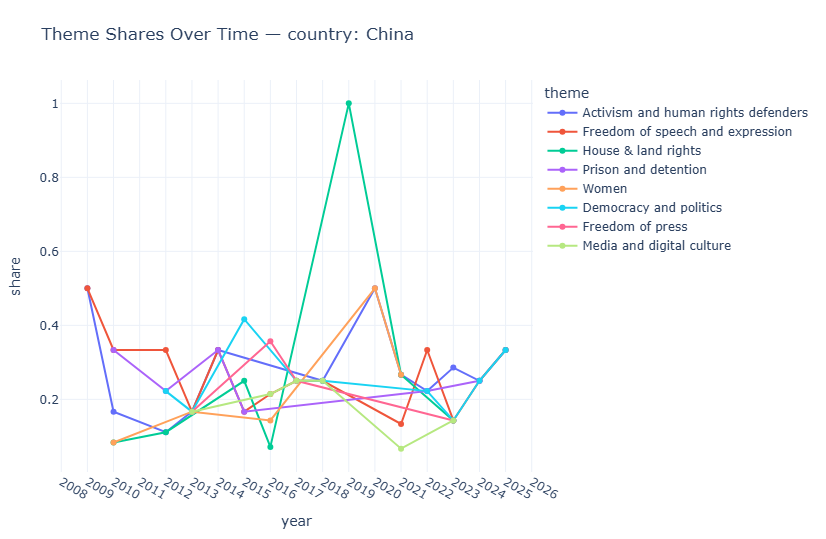

In [158]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="China", top_n=8)
fig.show()

### Analysis:
__RQ: How do the shares of the most common themes in China change over time?__

- 2009: Two themes start relatively high (around ~0.5), then quickly drop in the following years.

- 2010–2013: Shares are more balanced, with most themes clustered in the ~0.1–0.3 range.

- 2014–2016: Several themes trade places with moderate peaks (roughly ~0.3–0.4), but none dominates for long.

- 2019: One theme spikes dramatically to ~1.0, meaning it dominates that year’s China-related movies in your data.

- 2020: A couple themes rise to about ~0.5, creating another short period of higher concentration.

- 2021–2025: Shares settle back into mostly moderate levels (~0.15–0.3), with a small uptick for one theme by 2025 (around ~0.33).

The peak in films from China addressing house and land rights between 2016 and 2021 likely reflects ongoing domestic social and political issues related to urbanization, property disputes, and forced evictions. During this period, rapid urban development, land requisitions, and housing policies may have generated public debate and social tensions, which filmmakers chose to document and critique.

### Syria

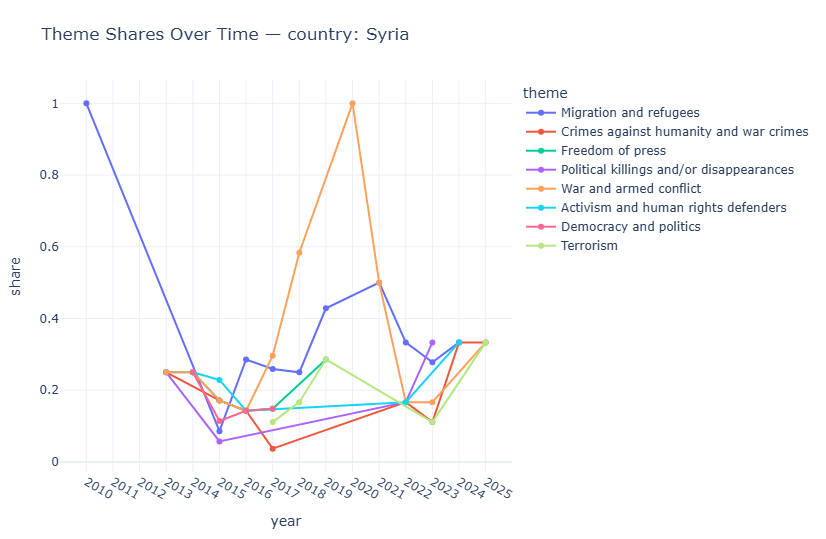

In [159]:
def theme_trends_over_time(data, group_col, group_value, top_n=8):
    d = data[data[group_col] == group_value].copy()

    #pick top themes overall within this group (to keep plot readable)
    top_themes = d["theme"].value_counts().head(top_n).index
    d = d[d["theme"].isin(top_themes)]

    counts = d.groupby(["year", "theme"]).size().reset_index(name="count")
    totals = d.groupby(["year"]).size().reset_index(name="total")
    out = counts.merge(totals, on="year")
    out["share"] = out["count"] / out["total"]

    fig = px.line(
        out, x="year", y="share", color="theme",
        markers=True,
        title=f"Theme Shares Over Time — {group_col}: {group_value}",
        template="plotly_white"
    )
    fig.update_layout(width=1050, height=520, margin=dict(l=60, r=30, t=80, b=50))
    fig.update_xaxes(dtick=1)
    return fig

#per country
fig = theme_trends_over_time(long, group_col="country", group_value="Syria", top_n=8)
fig.show()

### Analysis:
__RQ: How do the shares of the most common themes in Syria change over time?__

- 2010: One theme dominates completely (share ~1.0), indicating all Syria-related movies that year in your data focus on that theme.

- 2013–2016: Shares drop into a more mixed pattern, with most themes clustered around ~0.1–0.3 and no single clear leader.

- 2017–2020: War and armed conflict rises strongly, peaking at ~1.0 in 2020, showing a highly concentrated focus during this period.

- 2021: The distribution becomes less concentrated, with the top themes closer together (around ~0.5 for the leading themes).

- 2022–2023: Shares converge again near ~0.15–0.35, suggesting a more balanced theme mix.

- 2024–2025: Several themes increase and align around ~0.33, indicating a relatively even spread across multiple themes in the most recent years.

The dominance of “War and armed conflicts” underscores the profound impact of the Syrian civil war on the country's cinema. These themes reflect the realities of conflict, displacement, and human rights abuses, which have defined Syria's recent history.

# Critical thinking exercise

### Selection Bias in Film Archive Curation

Based on the Heatmap of Themes Addressed in Specific Countries, are some human rights themes over- or underrepresented in certain regions? How might these patterns relate to current social and political issues, and what impact could they have on the Movies that Matter Festival’s goal of raising awareness and promoting global human rights?

In [160]:
# write your answer here









### Solution 

Based on Themes Addressed in Specific Countries, the heatmap reveals that certain human rights themes are overrepresented in specific regions, reflecting both the social and political context of those countries:
- Afghanistan, Iran, and India: The themes of women’s rights and, in Afghanistan’s case, war, dominate. This likely reflects ongoing gender inequality and conflict issues in these countries.
- China: Themes around freedom and activism are most frequent, aligning with the country’s political climate and restrictions on civil liberties.
- France: The archive emphasizes migration and refugees, reflecting current debates and policies on immigration in Europe.
- Germany and Syria: War is the dominant theme, likely tied to historical or ongoing conflict narratives.
- Netherlands: Family and women’s rights appear prominently, showing the curatorial focus on social issues in a domestic context.
- Palestine: War dominates, highlighting the persistent conflicts in the region.
- Russia: Democracy and politics are emphasized, reflecting political tensions and governance issues.
- United States: Activism, democracy, politics, and racism are most common, which mirrors contemporary social movements and public discourse.

These patterns suggest that the curatorial choices emphasize the themes most salient to each country’s social and political situation. As a result, some issues may be overrepresented (e.g., women’s rights in Iran and Afghanistan, war in Syria), while other global issues may be underrepresented (e.g., climate change, economic inequality).

This distribution could affect the Movies that Matter Festival’s goal by shaping audiences’ perception of global human rights issues: viewers may see certain regions as defined by particular challenges, which can raise awareness but also risks oversimplifying complex situations or overlooking less highlighted themes.



The end part 2.